Choose wEE = (1 +)w
Hopf
EE for a small  > 0. (i) For τI = 10 and  = 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, integrate from a point close to (E, ¯ ¯I) until the oscillation has settled and report the period, the amplitude max E−min E
and the lag of the peaks of I behind those of E (in degrees). Plot the amplitude against  on log–log axes with a fitted
slope. (ii) For τI = 2, 3, 5, 7.5, 10, 15, 20 and  = 0.02, compare the simulated frequency with ω/2π from (b). (iii)
Plot E(t) and I(t) for τI = 10,  = 0.1. How do the period and the lag change as  grows, and why? Is the Hopf
bifurcation supercritical?

0.0050 12.6990 0.0197 73.5541
0.0100 12.8113 0.0279 71.3962
0.0200 13.0355 0.0394 68.3589
0.0500 13.7061 0.0621 62.5196
0.1000 14.8221 0.0874 56.5396
0.2000 17.0834 0.1231 49.7541


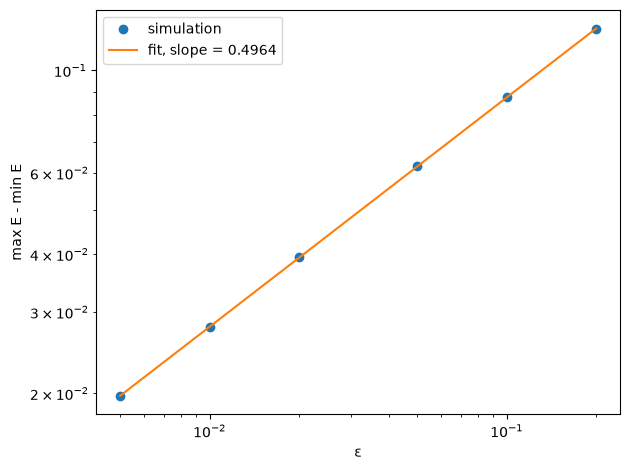

 tauI  f_sim(Hz)  f_lin(Hz)   ratio
2.0000 157.0592 162.7744 0.9649
3.0000 133.3989 138.0974 0.9660
5.0000 106.3555 110.0818 0.9661
7.5000 88.0159 91.1254 0.9659
10.0000 76.7134 79.4500 0.9656
15.0000 63.0214 65.3031 0.9651
20.0000 54.7370 56.7405 0.9647


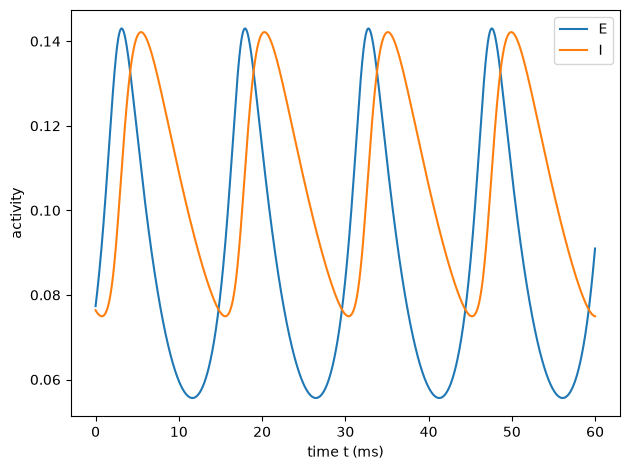

epsilon = -0.02: (E-Ebar) at end = 0.0000
epsilon = -0.05: (E-Ebar) at end = 0.0000


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks

# Parameters & equations
eta = 4.0
tauE = 5.0
wEI = 10.0
wIE = 10.0
E_bar = 0.1
I_bar = 0.1
X_bar = np.log(E_bar / (1-E_bar)) / eta
f = lambda x: 1/(1 + np.exp(-eta * x))
fpE = eta * E_bar * (1 - E_bar)
fpI = eta * I_bar * (1 - I_bar)
B = (eta ** 2 * wEI * wIE * E_bar * (1 - E_bar) * I_bar * (1 - I_bar)) / tauE

def wEE_hopf(tauI):
    return (1 + tauE / tauI) / fpE

def params(wEE):
    pE = X_bar - wEE * E_bar + wEI * I_bar
    pI = X_bar - wIE * E_bar
    return pE, pI

def rhs(t, y, tauI, wEE, pE, pI):
    E, I = y
    return [(-E + f(wEE * E - wEI * I + pE)) / tauE, (-I + f(wIE * E + pI)) / tauI]

def simulation(tauI, eps, d0 = 1e-3):
    wEE = (1 + eps) * wEE_hopf(tauI)
    pE, pI = params(wEE)
    args = (tauI, wEE, pE, pI)
    rate = abs(eps) * (1 + tauE / tauI) / (2 * tauE)
    T = max(1500, 40/rate)
    kw = dict(method = "DOP853", rtol = 1e-10, atol = 1e-12)
    s1 = solve_ivp(rhs, [0, T], [E_bar + d0, I_bar], args = args, **kw)
    t2 = np.arange(0, 40 * 2 * np.pi / np.sqrt(max(B / tauI - 1 / tauI ** 2, 1e-3)), 0.01)
    s2 = solve_ivp(rhs, [0, t2[-1]], s1.y[:, -1], args = args, t_eval = t2, ** kw)
    return s2.t, s2.y[0], s2.y[1]

def analysis(t, E, I):
    pe, _ = find_peaks(E); pi, _ = find_peaks(I)
    if len(pe) < 4:
        return dict(period = np.nan, amp = E.max() - E.min(), lag = np.nan)
    period = np.mean(np.diff(t[pe]))
    lags = []
    for k in pe[:-1]:
        nxt = pi[pi > k]
        if len(nxt): lags.append(t[nxt[0]] - t[k])
    lag = np.mean(lags) % period
    return dict(period = period, amp=E.max() - E.min(), lag = 360 * lag / period)

# part (i)
tauI = 10.0
epsilons = [0.005, 0.01, 0.02, 0.05, 0.1, 0.2]
results = []
for eps in epsilons:
    r = analysis(*simulation(tauI, eps))
    results.append(r)
    print(f"{eps:.4f} {r['period']:.4f} {r['amp']:.4f} {r['lag']:.4f}")
amp = np.array([r['amp'] for r in results])
slope, icpt = np.polyfit(np.log(epsilons), np.log(amp), 1)
plt.loglog(epsilons, amp, 'o', label = "simulation")
plt.loglog(epsilons, np.exp(icpt) * np.array(epsilons) ** slope, "-", label = f'fit, slope = {slope:.4f}')
plt.xlabel('ε')
plt.ylabel("max E - min E")
plt.legend();
plt.tight_layout()
plt.show()

# part (ii)
print(f"{'tauI':>5} {'f_sim(Hz)':>10} {'f_lin(Hz)':>10} {'ratio':>7}")
for tI in [2, 3, 5, 7.5, 10, 15, 20]:
    r = analysis(*simulation(tI, 0.02))
    f_sim = 1000/r['period']
    f_lin = 1000 * np.sqrt(B / tI - 1 / tI ** 2) / ( 2 * np.pi)
    print(f"{tI:.4f} {f_sim:.4f} {f_lin:.4f} {f_sim/f_lin:.4f}")

# part (iii)
t, E, I = simulation(10, 0.1)
m = t < 60
plt.plot(t[m], E[m], label = "E")
plt.plot(t[m], I[m], label = "I")
plt.xlabel('time t (ms)')
plt.ylabel('activity')
plt.legend()
plt.tight_layout()
plt.show()

# check if Hopf bifurcation is supercritical
for eps in [-0.02, -0.05]:
    tauI = 10
    wEE = (1 + eps) * wEE_hopf(tauI)
    pE, pI = params(wEE)
    s = solve_ivp(rhs, [0, 20000], [E_bar + 0.05, I_bar], args = (tauI, wEE, pE, pI), method = "DOP853", rtol = 1e-10, atol = 1e-12)
    print(f"epsilon = {eps}: (E-Ebar) at end = {abs(s.y[0, -1] - E_bar):.4f}")